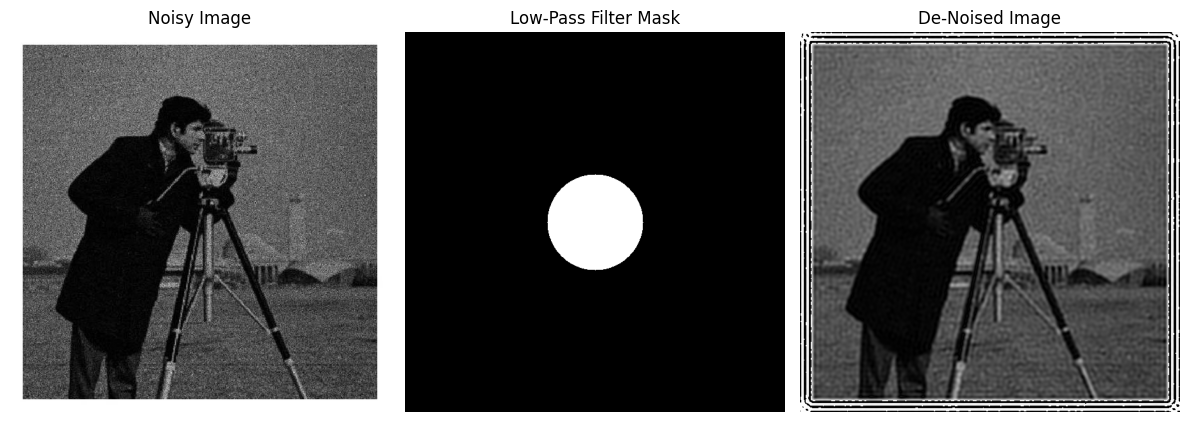

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# image in grayscale
img = cv2.imread("CameraManNoisy.jpg", cv2.IMREAD_GRAYSCALE)
if img is None:
    print("Error: Image not found!")
else:
    # Compute 2D FFT and shift zero frequency to center
    f = np.fft.fft2(img)
    fshift = np.fft.fftshift(f)

    # Low-pass circular mask
    rows, cols = img.shape
    crow, ccol = rows // 2, cols // 2
    radius = 75
    
    y, x = np.ogrid[:rows, :cols]
    mask = np.zeros((rows, cols), np.uint8)
    mask_area = (x - ccol)**2 + (y - crow)**2 <= radius**2
    mask[mask_area] = 1

    # Apply mask in frequency domain
    fshift_filtered = fshift * mask

    # Inverse FFT to get de-noised image
    img_denoised = np.fft.ifft2(np.fft.ifftshift(fshift_filtered))
    img_denoised = np.abs(img_denoised).astype(np.uint8)

    # Magnitude spectrum for mask visualization
    magnitude_spectrum_mask = 20 * np.log(np.abs(fshift_filtered) + 1)

    # Display results
    plt.figure(figsize=(12, 5))

    plt.subplot(1, 3, 1)
    plt.imshow(img, cmap='gray')
    plt.title('Noisy Image')
    plt.axis('off')

    plt.subplot(1, 3, 2)
    plt.imshow(mask, cmap='gray')
    plt.title('Low-Pass Filter Mask')
    plt.axis('off')

    plt.subplot(1, 3, 3)
    plt.imshow(img_denoised, cmap='gray')
    plt.title('De-Noised Image')
    plt.axis('off')

    plt.tight_layout()
    plt.show()
